# 07 · Regresión Gamma e índice de preselección territorial

**Proyecto integrador de Big Data y Analítica de Datos · American Tower del Perú**  
**Integrante:** Jeancarlo Morales Robles

La notebook entrena una regresión lineal generalizada de **Spark MLlib**, con familia Gamma y enlace log, para pronosticar la descarga móvil por distrito durante el trimestre siguiente. El modelo estima un valor positivo directamente en Mbps. El resultado es un candidato propio para la sección **4.3**. La selección definitiva del equipo requiere comparar las alternativas con las mismas reglas de evaluación. La sección **4.4** se sustenta con los Parquet dimensionales, cinco indicadores y el SQL de Athena.

El ajuste usa MLlib. La evaluación y el pronóstico aplican el enlace inverso en Spark SQL a partir de los coeficientes entrenados. Esta corrección evita el error de serialización observado en la ejecución de EMR.

**Ejecución en EMR.** Se usa un kernel nuevo `American Tower - PySpark` y se ejecutan todas las celdas en orden. La entrada es el manifiesto exitoso de la notebook 03 en S3. La configuración contiene el mismo manifiesto del experimento GBT adjunto. Basta cambiar `GOLD_RUN_URI` cuando se publique un Gold nuevo en el mismo entorno. La fecha y el período pronosticado se derivan del panel.

**Publicación.** La corrida escribe en prefijos nuevos por `run_id` y actualiza el objeto compartido de este modelo si `PUBLICAR_COMPATIBLE_QUICKSIGHT` está activo. `ATHENA_DATABASE` se ajusta al catálogo disponible antes de ejecutar el SQL. La notebook genera ese SQL y verifica los objetos en S3. El alta de vistas y la actualización de QuickSight requieren los permisos del entorno.

Fuente técnica: [Spark MLlib · GeneralizedLinearRegression](https://spark.apache.org/docs/3.5.9/api/python/reference/api/pyspark.ml.regression.GeneralizedLinearRegression.html).


## 1. Configuración

Se registran los buckets, el manifiesto y la identidad de la corrida. Los umbrales de 10 pruebas y dos teselas son reglas de suficiencia para revisión, no mínimos de entrenamiento. Los pesos 40/35/25 se prueban después con escenarios de sensibilidad.


In [1]:
import json
import math
import os
import re
import sys
import uuid
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display

MODEL_NAME = "glm_gamma_regressor"
MODEL_AUTHOR = "Jeancarlo Morales Robles"

REGION = "us-east-1"
OPERATIONS_BUCKET = "american-tower-dev-operations-1dd72256126674a5893dfca3df"
GOLD_BUCKET = "american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee"
ARTIFACTS_BUCKET = "american-tower-dev-artifacts-74d32893263161eaef72faf57a"
GOLD_RUN_URI = (
    f"s3://{OPERATIONS_BUCKET}/run_id=20261125T073334Z-7ea4f607ff/gold/_SUCCESS.json"
)
ATHENA_DATABASE = "american_tower"
PUBLICAR_COMPATIBLE_QUICKSIGHT = True
GENERAR_MAPA = True

EXECUTORS = 2
MIN_TESTS = 10
MIN_TESELAS = 2
TOP_K = 50
PESOS = (0.40, 0.35, 0.25)
REG_PARAMS = (0.01, 0.1, 1.0)
ID_ORIGEN_MIN = 2020 * 4
ANIO_VALIDACION = 2023
ANIO_PRUEBA = 2024

NOW = datetime.now(timezone.utc)
RUN_ID = f"{NOW:%Y%m%dT%H%M%SZ}-{uuid.uuid4().hex[:10]}"
GOLD_ROOT = f"s3://{GOLD_BUCKET}/run_id={RUN_ID}/consumo/{MODEL_NAME}"
OPS_ROOT = f"s3://{OPERATIONS_BUCKET}/run_id={RUN_ID}/modelo_{MODEL_NAME}"
ARTIFACT_ROOT = f"s3://{ARTIFACTS_BUCKET}/models/{MODEL_NAME}/run_id={RUN_ID}"
SHARED_URI = f"s3://{GOLD_BUCKET}/predicciones_modelos/modelo_{MODEL_NAME}.parquet"

assert re.fullmatch(r"[a-z][a-z0-9_]*", ATHENA_DATABASE), "Usar un nombre válido de base Athena."
assert math.isclose(sum(PESOS), 1.0), "Los pesos de prioridad deben sumar uno."

def mostrar(**values):
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame(values.items(), columns=["Indicador", "Valor"]))

mostrar(modelo=MODEL_NAME, autor=MODEL_AUTHOR, corrida=RUN_ID, manifiesto_gold=GOLD_RUN_URI,
        salida_dimensional=GOLD_ROOT, quicksight_compatible=PUBLICAR_COMPATIBLE_QUICKSIGHT,
        objeto_compartido=SHARED_URI, athena_database=ATHENA_DATABASE)


,Indicador,Valor
0,modelo,glm_gamma_regressor
1,autor,Jeancarlo Morales Robles
2,corrida,20261128T150840Z-69871f6269
3,manifiesto_gold,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T073334Z-7ea4f607ff/gold/_SUCCESS.json
4,salida_dimensional,s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/run_id=20261128T150840Z-69871f6269/consumo/glm_gamma_regressor
5,quicksight_compatible,True
6,objeto_compartido,s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/predicciones_modelos/modelo_glm_gamma_regressor.parquet
7,athena_database,american_tower


## 2. Linaje y sesión Spark

El manifiesto Gold identifica el panel y el contexto. El cómputo usa Spark sobre YARN en EMR. La celda imprime la aplicación y la ruta de eventos.


In [2]:
s3 = boto3.client("s3", region_name=REGION)

def s3_path(uri):
    bucket, slash, key = uri.removeprefix("s3://").partition("/")
    if not uri.startswith("s3://") or not bucket or not slash or not key:
        raise ValueError(f"URI S3 inválida: {uri}")
    return bucket, key

def leer_json(uri):
    bucket, key = s3_path(uri)
    with s3.get_object(Bucket=bucket, Key=key)["Body"] as stream:
        return json.load(stream)

def guardar(uri, data, mime):
    bucket, key = s3_path(uri)
    s3.put_object(Bucket=bucket, Key=key, Body=data, ContentType=mime)
    return uri

def guardar_figura(fig, nombre):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=170, bbox_inches="tight", facecolor="white")
    uri = guardar(f"{OPS_ROOT}/{nombre}", buf.getvalue(), "image/png")
    plt.show()
    plt.close(fig)
    print(uri)
    return uri

manifest = leer_json(GOLD_RUN_URI)
if manifest.get("schema") != "gold-autonomo-v2" or not manifest.get("complete"):
    raise ValueError("GOLD_RUN_URI debe apuntar al manifiesto de la notebook 03.")
for campo in ("panel_uri", "context_uri"):
    if s3_path(manifest[campo])[0] != GOLD_BUCKET:
        raise ValueError(f"El manifiesto apunta a un bucket diferente en {campo}.")

# El clúster aporta PySpark y el intérprete del kernel; no se instala software.
spark_home = Path("/usr/lib/spark")
if spark_home.is_dir():
    os.environ["SPARK_HOME"] = str(spark_home)
    os.environ["PYSPARK_PYTHON"] = sys.executable
    os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
    python_spark = spark_home / "python"
    sys.path[:0] = [str(python_spark), *map(str, sorted((python_spark / "lib").glob("py4j-*.zip")))]

from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GeneralizedLinearRegression, LinearRegression

eventos = guardar(
    f"s3://{OPERATIONS_BUCKET}/run_id={RUN_ID}/eventos_spark/", b"", "application/octet-stream"
)
spark = (
    SparkSession.builder.master("yarn")
    .appName(f"american-tower-{MODEL_NAME}")
    .config("spark.submit.deployMode", "client")
    .config("spark.dynamicAllocation.enabled", "false")
    .config("spark.executor.instances", str(EXECUTORS))
    .config("spark.executor.cores", "4")
    .config("spark.executor.memory", "8g")
    .config("spark.executor.memoryOverhead", "3g")
    .config("spark.sql.shuffle.partitions", "48")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.eventLog.enabled", "true")
    .config("spark.eventLog.dir", eventos)
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
if spark.sparkContext.master != "yarn":
    raise RuntimeError("Se requiere una sesión YARN. Reiniciar el kernel de EMR y ejecutar desde el inicio.")

mostrar(spark=spark.version, aplicacion=spark.sparkContext.applicationId,
        ejecucion_gold=manifest["run_id"], panel=manifest["panel_uri"], contexto=manifest["context_uri"],
        eventos_spark=eventos)


/opt/american-tower/venv/lib64/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
Nov 28, 2026 3:08:41 PM org.apache.spark.launcher.Log4jHotPatchOption staticJavaAgentOption

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/28 15:08:46 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


,Indicador,Valor
0,spark,3.5.0-amzn-1
1,aplicacion,application_1795877894672_0002
2,ejecucion_gold,20261125T073334Z-7ea4f607ff
3,panel,s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/run_id=20261125T073334Z-7ea4f607ff/panel_distrital
4,contexto,s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/run_id=20261125T073334Z-7ea4f607ff/contexto_territorial
5,eventos_spark,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261128T150840Z-69871f6269/eventos_spark/


## 3. Preparación de pares y validación temporal

La fila de origen aporta solo datos conocidos hasta el trimestre \(t\). Se usa la descarga de \(t\), su media móvil de hasta cuatro trimestres observados en \([t-3,t]\), el cambio respecto de \(t-1\), el número de pruebas y el trimestre calendario objetivo. Si falta \(t-1\), el cambio se fija en cero. Los pares exigen observación en \(t\) y \(t+1\).

El origen se limita desde 2020-T1 para replicar el protocolo del informe. Se ajusta con objetivos de 2020–2022, se selecciona con 2023 y se reporta el error de prueba en 2024. Población 2020 y cobertura OSIPTEL 2023 se mantienen como contexto para el índice; la regresión no las consulta.


In [3]:
panel = spark.read.parquet(manifest["panel_uri"]).select(
    "ubigeo", "period_id", "observado", "vel_descarga_mbps", "tests", "teselas_observadas"
)
contexto = spark.read.parquet(manifest["context_uri"]).select(
    "ubigeo", "departamento", "provincia", "distrito", "poblacion_2020",
    "centros_con_dato_4g", "centros_con_4g_declarada", "fecha_corte_fuente"
)
calidad = panel.agg(
    F.count("*").alias("filas"),
    F.countDistinct(F.struct("ubigeo", "period_id")).alias("claves"),
    F.countDistinct("ubigeo").alias("distritos"),
    F.countDistinct("period_id").alias("periodos"),
    F.min("period_id").alias("primero"),
    F.max("period_id").alias("ultimo"),
).first()
n_distritos = calidad.distritos
if (
    not n_distritos or calidad.filas != calidad.claves
    or calidad.filas != calidad.distritos * calidad.periodos
    or calidad.periodos != calidad.ultimo - calidad.primero + 1
    or calidad.filas != manifest["panel"]["filas"]
):
    raise ValueError("El panel Gold debe ser rectangular, con períodos consecutivos y sin claves duplicadas.")
if (contexto.count() != n_distritos or contexto.select("ubigeo").distinct().count() != n_distritos
    or panel.select("ubigeo").distinct().join(contexto, "ubigeo", "left_anti").take(1)
    or contexto.filter(~F.col("ubigeo").rlike("^[0-9]{6}$") | F.col("ubigeo").isNull()).take(1)):
    raise ValueError("El contexto debe tener una fila por UBIGEO y coincidir con el panel.")

vel = F.col("vel_descarga_mbps")
vel_valida = vel.isNotNull() & (~F.isnan(vel)) & (vel > 0) & (vel < float("inf"))
if panel.filter(
    F.col("observado").isNull()
    | (F.col("observado") != vel_valida)
    | (F.col("observado") & ((F.coalesce(F.col("tests"), F.lit(0)) <= 0)
                            | (F.coalesce(F.col("teselas_observadas"), F.lit(0)) <= 0)))
    | (~F.col("observado") & vel.isNotNull())
).take(1):
    raise ValueError("Cada observación debe tener descarga finita estrictamente positiva y soporte válido.")

w = Window.partitionBy("ubigeo").orderBy("period_id")
w4 = w.rowsBetween(-3, 0)
FEATURES = [
    "log_vel_t", "log_media_4t", "variacion_log_t", "log_tests_t",
    "objetivo_t2", "objetivo_t3", "objetivo_t4",
]
# La ventana excluye 2019 para reproducir también la preparación de la línea base.
x = (panel.filter(F.col("period_id") >= ID_ORIGEN_MIN)
     .withColumnRenamed("vel_descarga_mbps", "vel_t")
     .withColumn("media_4t", F.avg("vel_t").over(w4))
     .withColumn("vel_anterior", F.lag("vel_t").over(w))
     .withColumn("objetivo", F.lead("vel_t").over(w))
     .withColumn("period_id_objetivo", F.col("period_id") + 1)
     .withColumn("year_objetivo", F.floor(F.col("period_id_objetivo") / 4).cast("int"))
     .withColumn("quarter_objetivo", (F.pmod("period_id_objetivo", F.lit(4)) + 1).cast("int"))
     .withColumn("log_vel_t", F.log1p("vel_t"))
     .withColumn("log_media_4t", F.log1p("media_4t"))
     .withColumn("variacion_log_t", F.col("log_vel_t") - F.log1p(F.coalesce("vel_anterior", "vel_t")))
     .withColumn("log_tests_t", F.log1p("tests")))

for q in (2, 3, 4):
    x = x.withColumn(f"objetivo_t{q}", (F.col("quarter_objetivo") == q).cast("double"))

observados = x.filter("observado").cache()
pares = observados.filter(F.col("objetivo").isNotNull()).cache()
train = pares.filter(F.col("year_objetivo") < ANIO_VALIDACION)
val = pares.filter(F.col("year_objetivo") == ANIO_VALIDACION)
test = pares.filter(F.col("year_objetivo") == ANIO_PRUEBA)
conteos = (pares.groupBy("year_objetivo").agg(
    F.count("*").alias("pares"), F.countDistinct("ubigeo").alias("distritos"))
    .orderBy("year_objetivo").toPandas())
n_train = int(conteos.loc[conteos.year_objetivo < ANIO_VALIDACION, "pares"].sum())
n_val = int(conteos.loc[conteos.year_objetivo == ANIO_VALIDACION, "pares"].sum())
n_test = int(conteos.loc[conteos.year_objetivo == ANIO_PRUEBA, "pares"].sum())
if min(n_train, n_val, n_test) == 0:
    raise ValueError("Se requiere al menos un par supervisado en entrenamiento, validación y prueba.")

def trimestre(period_id):
    return f"{period_id // 4}-T{period_id % 4 + 1}"

p_actual = int(calidad.ultimo)
p_previo = p_actual - 1
mostrar(distritos=n_distritos, filas=int(calidad.filas), corte_gold=trimestre(p_actual),
        pares_entrenamiento=n_train, pares_validacion=n_val, pares_prueba=n_test,
        reproduce_tamanos_informe=(n_train, n_val, n_test) == (13660, 5248, 5666))
display(conteos)


,Indicador,Valor
0,distritos,1890
1,filas,54810
2,corte_gold,2026-T1
3,pares_entrenamiento,13660
4,pares_validacion,5248
5,pares_prueba,5666
6,reproduce_tamanos_informe,True


,year_objetivo,pares,distritos
0,2020,3190,1335
1,2021,5126,1547
2,2022,5344,1574
3,2023,5248,1547
4,2024,5666,1645
5,2025,5912,1662
6,2026,1450,1450


## 4. Ajuste con Spark MLlib

Se ajustan tres valores de regularización Gamma y se elige por MAE de validación. Ante empate se usa RMSE. La regresión lineal de una variable reproduce la alternativa del avance y se ajusta con el mismo entrenamiento. Los coeficientes de Gamma describen asociaciones, con escala logarítmica de la media condicional, y no identifican efectos de inversión.


In [4]:
def fit_gamma(frame, reg):
    return Pipeline(stages=[
        VectorAssembler(inputCols=FEATURES, outputCol="features_gamma"),
        GeneralizedLinearRegression(
            family="gamma", link="log", featuresCol="features_gamma", labelCol="objetivo",
            predictionCol="pred_gamma", solver="irls", regParam=reg, maxIter=60, tol=1e-6,
        ),
    ]).fit(frame)


def parametros_ajustados(etapa, columnas):
    coeficientes = [float(valor) for valor in etapa.coefficients]
    intercepto = float(etapa.intercept)
    if len(coeficientes) != len(columnas) or not all(
        math.isfinite(valor) for valor in [intercepto, *coeficientes]
    ):
        raise ValueError("El ajuste produjo coeficientes inválidos para su esquema de características.")
    return {"intercepto": intercepto, "coeficientes": dict(zip(columnas, coeficientes))}


def predictor_lineal(parametros):
    resultado = F.lit(parametros["intercepto"])
    for columna, peso in parametros["coeficientes"].items():
        resultado = resultado + F.col(columna) * F.lit(peso)
    return resultado


def predecir_gamma(frame, parametros):
    # El enlace log se invierte en Spark SQL usando solo los coeficientes del ajuste.
    return frame.withColumn("pred_gamma", F.exp(predictor_lineal(parametros)))


def metricas_expr(pred_col):
    pred = F.col(pred_col)
    error = pred - F.col("objetivo")
    invalida = pred.isNull() | F.isnan(pred) | (F.abs(pred) == float("inf"))
    return (
        F.count("*").alias("n"),
        F.sum(F.when(invalida, 1).otherwise(0)).alias("invalidas"),
        F.avg(F.abs(error)).alias("mae_mbps"),
        F.avg(error * error).alias("mse"),
        F.avg(error).alias("sesgo_mbps"),
        F.var_pop("objetivo").alias("var_objetivo"),
    )

def metricas(row):
    if row.invalidas:
        raise ValueError(f"Se encontraron {row.invalidas} predicciones no finitas.")
    if not row.n:
        return {"n": 0, "mae_mbps": None, "rmse_mbps": None, "sesgo_mbps": None, "r2": None}
    return {
        "n": int(row.n), "mae_mbps": float(row.mae_mbps), "rmse_mbps": math.sqrt(row.mse),
        "sesgo_mbps": float(row.sesgo_mbps),
        "r2": float(1 - row.mse / row.var_objetivo) if row.var_objetivo else None,
    }

ajustes = []
best_model = None
best_key = (float("inf"), float("inf"))
for reg in REG_PARAMS:
    candidato = fit_gamma(train, reg)
    etapa_gamma = candidato.stages[-1]
    parametros = parametros_ajustados(etapa_gamma, FEATURES)
    score = metricas(predecir_gamma(val, parametros).agg(*metricas_expr("pred_gamma")).first())
    ajustes.append({"reg_param": reg, "iteraciones": etapa_gamma.summary.numIterations, **score})
    criterio = (score["mae_mbps"], score["rmse_mbps"])
    if criterio < best_key:
        best_key, best_reg, best_model = criterio, reg, candidato
        parametros_gamma_eval = parametros

lin = Pipeline(stages=[
    VectorAssembler(inputCols=["vel_t"], outputCol="features_lineal"),
    LinearRegression(featuresCol="features_lineal", labelCol="objetivo", predictionCol="pred_lineal",
                     regParam=0.0, solver="normal"),
]).fit(train)
parametros_lineal = parametros_ajustados(lin.stages[-1], ["vel_t"])

coef = pd.DataFrame({
    "caracteristica": ["intercepto", *FEATURES],
    "coeficiente_gamma": [parametros_gamma_eval["intercepto"], *parametros_gamma_eval["coeficientes"].values()],
})
display(pd.DataFrame(ajustes).sort_values(["mae_mbps", "rmse_mbps"]))
mostrar(reg_param_elegido=best_reg, criterio="MAE de validación; empate por RMSE",
        motor_pronostico="Spark SQL",
        intercepto_linea_base=parametros_lineal["intercepto"],
        coeficiente_linea_base=parametros_lineal["coeficientes"]["vel_t"])
display(coef)


26/11/28 15:09:22 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/28 15:09:22 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS
26/11/28 15:09:22 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK
26/11/28 15:09:30 WARN Instrumentation: [4cda8412] regParam is zero, which might cause numerical instability and overfitting.


,reg_param,iteraciones,n,mae_mbps,rmse_mbps,sesgo_mbps,r2
0,0.01,9,5248,11.260581,18.686072,-4.846269,0.068274
1,0.10,8,5248,11.384383,18.923950,-5.340138,0.044401
2,1.00,8,5248,12.165441,20.002512,-7.022472,-0.067631


,Indicador,Valor
0,reg_param_elegido,0.01
1,criterio,MAE de validación; empate por RMSE
2,motor_pronostico,Spark SQL
3,intercepto_linea_base,11.921545
4,coeficiente_linea_base,0.380835


,caracteristica,coeficiente_gamma
0,intercepto,1.545350
1,log_vel_t,0.195798
2,log_media_4t,0.289383
3,variacion_log_t,-0.053179
4,log_tests_t,-0.006025
5,objetivo_t2,0.038276
6,objetivo_t3,0.054086
7,objetivo_t4,0.057581


## 5. Evaluación comparativa

La selección de hiperparámetros termina antes de calcular las métricas de 2024. Se reportan MAE, RMSE, sesgo y R² para las mismas filas de cada corte. La cohorte de soporte suficiente se presenta por separado. Un sesgo negativo puede elevar la prioridad aparente de un distrito; el signo opuesto puede ocultar un distrito que amerita revisión.

La notebook GBT ejecutada aporta otra alternativa del equipo. Incluye contexto estático entre sus variables y usa pares con origen anterior a 2020. Sus resultados requieren alinear el protocolo antes de usarlos para declarar un ganador.


,particion,segmento,modelo,n,mae_mbps,rmse_mbps,sesgo_mbps,r2
0,validacion,Todos los pares,Persistencia,5248,13.2788,21.7215,-1.2451,-0.2590
1,validacion,Todos los pares,Regresión lineal,5248,11.6445,19.0843,-5.1307,0.0281
2,validacion,Todos los pares,Gamma log,5248,11.2606,18.6861,-4.8463,0.0683
3,validacion,Con soporte mínimo,Persistencia,3316,10.0615,15.6523,-1.1071,-0.0632
4,validacion,Con soporte mínimo,Regresión lineal,3316,9.4825,14.7144,-4.9762,0.0604
5,validacion,Con soporte mínimo,Gamma log,3316,9.1417,14.4222,-4.4026,0.0973
6,prueba,Todos los pares,Persistencia,5666,14.6482,23.6439,-1.4865,-0.4802
7,prueba,Todos los pares,Regresión lineal,5666,13.0288,20.2239,-7.6829,-0.0829
8,prueba,Todos los pares,Gamma log,5666,12.2873,19.5343,-7.1663,-0.0103
9,prueba,Con soporte mínimo,Persistencia,3990,11.4361,16.7262,-1.9423,-0.1737


,Indicador,Valor
0,mejora_mae_vs_base_mbps,0.741436
1,mejora_rmse_vs_persistencia_pct,17.381558
2,cumple_meta_rmse_15pct,True


,departamento,pares,mae_persistencia,mae_lineal,mae_gamma,sesgo_gamma
0,CUSCO,435,13.683,12.575,11.968,-7.941
1,LIMA,425,14.652,15.964,14.664,-11.672
2,JUNIN,398,14.640,12.734,12.320,-6.218
3,CAJAMARCA,392,17.148,13.179,12.413,-5.762
4,ANCASH,388,15.665,13.490,12.766,-6.275
5,PUNO,383,14.061,12.032,11.209,-5.450
6,AREQUIPA,346,16.083,14.788,14.064,-9.555
7,AYACUCHO,337,14.441,12.794,12.270,-7.233
8,LA LIBERTAD,279,12.571,10.651,10.138,-3.578
9,HUANCAVELICA,274,14.584,13.137,12.584,-8.282


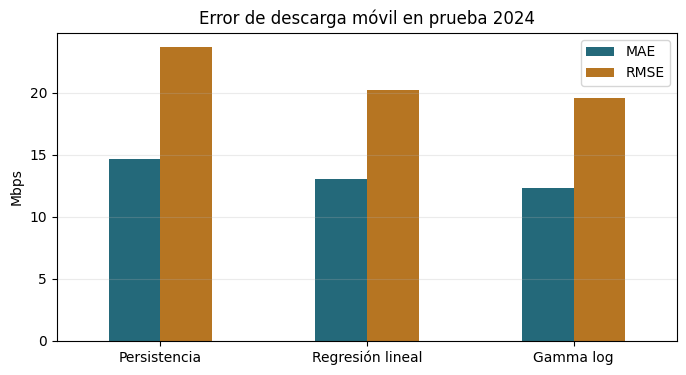

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261128T150840Z-69871f6269/modelo_glm_gamma_regressor/evaluacion_gamma.png


DataFrame[ubigeo: string, period_id: int, observado: boolean, vel_t: double, tests: bigint, teselas_observadas: bigint, media_4t: double, vel_anterior: double, objetivo: double, period_id_objetivo: int, year_objetivo: int, quarter_objetivo: int, log_vel_t: double, log_media_4t: double, variacion_log_t: double, log_tests_t: double, objetivo_t2: double, objetivo_t3: double, objetivo_t4: double, pred_gamma: double, pred_lineal: double, departamento: string]

In [5]:
def evaluar(frame):
    predicciones = predecir_gamma(frame, parametros_gamma_eval).withColumn(
        "pred_lineal", predictor_lineal(parametros_lineal)
    )
    return predicciones.join(
        contexto.select("ubigeo", "departamento"), "ubigeo", "inner"
    )

nombres = {"vel_t": "Persistencia", "pred_lineal": "Regresión lineal", "pred_gamma": "Gamma log"}
soporte = (F.col("tests") >= MIN_TESTS) & (F.col("teselas_observadas") >= MIN_TESELAS)
val_scored, test_scored = evaluar(val).cache(), evaluar(test).cache()
comparacion = []
for corte, frame in (("validacion", val_scored), ("prueba", test_scored)):
    for segmento, sub in (("Todos los pares", frame), ("Con soporte mínimo", frame.filter(soporte))):
        for pred, nombre in nombres.items():
            comparacion.append({
                "particion": corte, "segmento": segmento, "modelo": nombre,
                **metricas(sub.agg(*metricas_expr(pred)).first()),
            })

tabla_metricas = pd.DataFrame(comparacion)
display(tabla_metricas.round(4))
prueba_todos = tabla_metricas[
    (tabla_metricas.particion == "prueba") & (tabla_metricas.segmento == "Todos los pares")
].set_index("modelo")
mae_gamma = float(prueba_todos.loc["Gamma log", "mae_mbps"])
mae_lineal = float(prueba_todos.loc["Regresión lineal", "mae_mbps"])
rmse_gamma = float(prueba_todos.loc["Gamma log", "rmse_mbps"])
rmse_pers = float(prueba_todos.loc["Persistencia", "rmse_mbps"])
reduccion_rmse = (1 - rmse_gamma / rmse_pers) * 100 if rmse_pers > 0 else None
mostrar(mejora_mae_vs_base_mbps=mae_lineal - mae_gamma, mejora_rmse_vs_persistencia_pct=reduccion_rmse,
        cumple_meta_rmse_15pct=(reduccion_rmse is not None and reduccion_rmse >= 15))

diag = (test_scored.groupBy("departamento").agg(
    F.count("*").alias("pares"),
    F.avg(F.abs(F.col("vel_t") - F.col("objetivo"))).alias("mae_persistencia"),
    F.avg(F.abs(F.col("pred_lineal") - F.col("objetivo"))).alias("mae_lineal"),
    F.avg(F.abs(F.col("pred_gamma") - F.col("objetivo"))).alias("mae_gamma"),
    F.avg(F.col("pred_gamma") - F.col("objetivo")).alias("sesgo_gamma"),
).orderBy(F.desc("pares"), "departamento").toPandas())
display(diag.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
prueba_todos[["mae_mbps", "rmse_mbps"]].plot.bar(ax=ax, color=["#24697a", "#b67522"], rot=0)
ax.set(title="Error de descarga móvil en prueba 2024", xlabel="", ylabel="Mbps")
ax.legend(["MAE", "RMSE"])
ax.grid(axis="y", alpha=0.25)
chart_eval = guardar_figura(fig, "evaluacion_gamma.png")
val_scored.unpersist()
test_scored.unpersist()


## 6. Artefactos de evaluación y pronóstico

La versión de evaluación usa solo el entrenamiento de 2020–2022. La versión de pronóstico se vuelve a ajustar con todos los pares disponibles hasta el último trimestre Gold, con la regularización ya elegida. El ajuste del corte anterior también respeta su propia fecha para medir estabilidad entre dos pronósticos.


In [6]:
def pares_hasta(period_id):
    return pares.filter(F.col("period_id_objetivo") <= period_id)

# Se ajusta una versión distinta para pronósticos y otra para el corte anterior.
ajuste_prod = pares_hasta(p_actual)
prod_model = fit_gamma(ajuste_prod, best_reg)
modelo_anterior = fit_gamma(pares_hasta(p_previo), best_reg)
parametros_gamma_prod = parametros_ajustados(prod_model.stages[-1], FEATURES)
parametros_gamma_anterior = parametros_ajustados(modelo_anterior.stages[-1], FEATURES)

eval_uri = f"{ARTIFACT_ROOT}/evaluacion"
prod_uri = f"{ARTIFACT_ROOT}/productivo"
best_model.write().save(eval_uri)
prod_model.write().save(prod_uri)
contrato_uri = guardar(
    f"{ARTIFACT_ROOT}/contrato_caracteristicas.json",
    json.dumps({
        "gold_manifest_uri": GOLD_RUN_URI, "features": FEATURES,
        "family": "gamma", "link": "log", "reg_param": best_reg,
        "motor_pronostico": "Spark SQL",
        "formula_pronostico": "exp(intercepto + sum(peso * valor de la característica))",
        "parametros_evaluacion": parametros_gamma_eval,
        "parametros_productivos": parametros_gamma_prod,
        "historico_minimo": trimestre(ID_ORIGEN_MIN),
        "periodo_corte": trimestre(p_actual), "periodo_objetivo": trimestre(p_actual + 1),
        "media_movil": "Media de observaciones disponibles entre t-3 y t.",
        "cambio_log": "Si falta t-1, se usa t y el cambio es cero.",
        "poblacion_osiptel": "Solo contexto territorial; fuera de las características de Gamma.",
    }, ensure_ascii=False, indent=2, allow_nan=False).encode("utf-8"),
    "application/json",
)
mostrar(pares_productivos=ajuste_prod.count(), corte_productivo=trimestre(p_actual),
        horizonte=trimestre(p_actual + 1), modelo_evaluacion=eval_uri,
        modelo_productivo=prod_uri, contrato_caracteristicas=contrato_uri)


,Indicador,Valor
0,pares_productivos,31936
1,corte_productivo,2026-T1
2,horizonte,2026-T2
3,modelo_evaluacion,s3://american-tower-dev-artifacts-74d32893263161eaef72faf57a/models/glm_gamma_regressor/run_id=20261128T150840Z-69871f6269/evaluacion
4,modelo_productivo,s3://american-tower-dev-artifacts-74d32893263161eaef72faf57a/models/glm_gamma_regressor/run_id=20261128T150840Z-69871f6269/productivo
5,contrato_caracteristicas,s3://american-tower-dev-artifacts-74d32893263161eaef72faf57a/models/glm_gamma_regressor/run_id=20261128T150840Z-69871f6269/contrato_caracteristicas.json


## 7. Pronóstico e índice territorial

Se pronostican los distritos con velocidad observada en el último trimestre. Para recibir un índice deben cumplir umbrales de pruebas y teselas y contar con población y una declaración 4G interpretable al corte. El universo completo se conserva en la tabla de hechos con los cuatro estados de evidencia.

El índice en escala de 0 a 100 pondera debilidad de descarga proyectada, población y brecha en la declaración 4G. Para velocidad se usa el inverso del percentil y para población el percentil, ambos entre los distritos clasificables. Para 4G se usa uno menos la proporción de centros poblados con declaración positiva. Los valores faltantes no se imputan y el índice conserva nulo cuando la información es insuficiente. El ranking sirve para organizar la revisión inicial de distritos.


In [7]:
def generar_pronostico(periodo, parametros):
    origen = x.filter(F.col("period_id") == periodo).drop("objetivo")
    predichos = predecir_gamma(origen.filter("observado"), parametros).select("ubigeo", "pred_gamma")
    columnas = [
        "ubigeo", "observado", "period_id", "period_id_objetivo", "year_objetivo", "quarter_objetivo",
        F.col("vel_t").alias("vel_origen_mbps"), "tests", "teselas_observadas",
    ]
    resultado = (origen.select(*columnas).join(predichos, "ubigeo", "left")
                 .join(contexto, "ubigeo", "inner")
                 .withColumnRenamed("pred_gamma", "pred_descarga_mbps").toPandas())
    validas = resultado.loc[resultado["observado"], "pred_descarga_mbps"]
    if (validas.empty or len(resultado) != n_distritos or not resultado["ubigeo"].is_unique
        or not np.isfinite(validas).all() or not (validas > 0).all()):
        raise ValueError("El pronóstico no concilia con el universo o tiene predicciones no válidas.")

    fecha_origen = pd.Period(f"{periodo // 4}Q{periodo % 4 + 1}", freq="Q").end_time.normalize()
    corte = pd.to_datetime(resultado["fecha_corte_fuente"])
    interpretable = (
        (resultado["centros_con_dato_4g"] > 0)
        & (resultado["centros_con_4g_declarada"] >= 0)
        & (resultado["centros_con_4g_declarada"] <= resultado["centros_con_dato_4g"])
        & (corte <= fecha_origen)
    )
    resultado["pct_4g_declarada"] = (
        100 * resultado.loc[interpretable, "centros_con_4g_declarada"]
        / resultado.loc[interpretable, "centros_con_dato_4g"]
    )
    suficiente = (
        (resultado["tests"] >= MIN_TESTS) & (resultado["teselas_observadas"] >= MIN_TESELAS)
    )
    con_contexto = interpretable & resultado["poblacion_2020"].ge(0) & np.isfinite(resultado["poblacion_2020"])
    resultado["estado_evidencia"] = np.select(
        [~resultado["observado"], ~suficiente, ~con_contexto],
        ["sin_telemetria", "bajo_soporte", "sin_contexto"], default="clasificable",
    )
    return resultado

def percentil(serie):
    if len(serie) < 2:
        return serie * 0 + 0.5
    return (serie.rank(method="average") - 1) / (len(serie) - 1)

def priorizar(frame, pesos):
    salida = frame.copy()
    aptos = salida["estado_evidencia"].eq("clasificable")
    base = salida.loc[aptos]
    v, p, c = pesos
    salida["score_velocidad"] = 1 - percentil(base["pred_descarga_mbps"])
    salida["score_poblacion"] = percentil(base["poblacion_2020"])
    salida["score_brecha_4g"] = 1 - base["pct_4g_declarada"] / 100
    salida["indice_prioridad"] = 100 * (
        v * salida["score_velocidad"] + p * salida["score_poblacion"] + c * salida["score_brecha_4g"]
    )
    orden = salida.loc[aptos].sort_values(["indice_prioridad", "ubigeo"], ascending=[False, True]).index
    salida["ranking_prioridad"] = pd.Series(pd.NA, index=salida.index, dtype="Int64")
    salida.loc[orden, "ranking_prioridad"] = range(1, len(orden) + 1)
    return salida

actual = priorizar(generar_pronostico(p_actual, parametros_gamma_prod), PESOS)
previo = priorizar(generar_pronostico(p_previo, parametros_gamma_anterior), PESOS)
mostrar(origen=trimestre(p_actual), objetivo=trimestre(p_actual + 1), universo=len(actual),
        con_pronostico=int(actual["pred_descarga_mbps"].count()),
        con_prioridad=int(actual["indice_prioridad"].count()))
display(actual["estado_evidencia"].value_counts().rename_axis("estado").reset_index(name="distritos"))
top = actual.dropna(subset=["ranking_prioridad"]).nsmallest(TOP_K, "ranking_prioridad")
display(top[["ranking_prioridad", "ubigeo", "departamento", "distrito",
             "pred_descarga_mbps", "tests", "pct_4g_declarada", "indice_prioridad"]].head(20))


,Indicador,Valor
0,origen,2026-T1
1,objetivo,2026-T2
2,universo,1890
3,con_pronostico,1564
4,con_prioridad,908


,estado,distritos
0,clasificable,908
1,bajo_soporte,545
2,sin_telemetria,326
3,sin_contexto,111


,ranking_prioridad,ubigeo,departamento,distrito,pred_descarga_mbps,tests,pct_4g_declarada,indice_prioridad
1405,1,120303,JUNIN,PICHANAQUI,27.782978,288.0,9.523810,92.503281
317,2,120608,JUNIN,RIO TAMBO,31.705769,393.0,0.000000,90.815877
1874,3,160601,LORETO,CONTAMANA,24.181761,125.0,11.111111,89.565111
57,4,160403,LORETO,YAVARI,24.225766,77.0,0.000000,88.825799
706,5,160401,LORETO,RAMON CASTILLA,21.988328,216.0,16.666667,88.347115
1452,6,220708,SAN MARTIN,SHAMBOYACU,24.329935,11.0,0.000000,88.120176
1304,7,160402,LORETO,PEBAS,27.271190,31.0,0.000000,87.089305
1429,8,160301,LORETO,NAUTA,27.828183,189.0,15.384615,87.013824
1000,9,160305,LORETO,URARINAS,25.373354,15.0,0.000000,86.681367
1112,10,220105,SAN MARTIN,SORITOR,27.061915,66.0,33.333333,85.426314


## 8. Estabilidad y mapa

Se mide coincidencia del Top 50, Jaccard y correlación de Spearman con el corte anterior y para tres conjuntos alternativos de pesos. La comparación temporal incluye cambios de datos, composición de distritos y ajuste. El mapa usa la cartografía Bronze enlazada al manifiesto. `GENERAR_MAPA = False` permite omitir el mapa si el entorno carece de GeoPandas o `bsdtar`.


,prueba,k_solicitado,top_a,top_b,coincidencias,jaccard,clasificados_comunes,spearman
0,Temporal con ajuste al horizonte disponible,50,50,50,37,0.5873,777,0.9150
1,Mayor peso de velocidad,50,50,50,47,0.8868,908,0.9856
2,Mayor peso de población,50,50,50,44,0.7857,908,0.9687
3,Mayor peso de brecha 4G,50,50,50,42,0.7241,908,0.9407


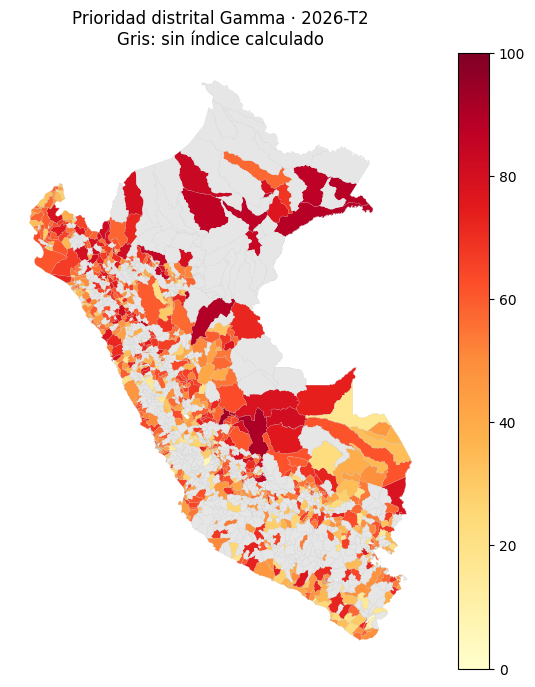

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261128T150840Z-69871f6269/modelo_glm_gamma_regressor/mapa_prioridad_gamma.png


In [8]:
def estabilidad(a, b, k):
    top_a = set(a.dropna(subset=["ranking_prioridad"]).nsmallest(k, "ranking_prioridad")["ubigeo"])
    top_b = set(b.dropna(subset=["ranking_prioridad"]).nsmallest(k, "ranking_prioridad")["ubigeo"])
    comunes = a[["ubigeo", "indice_prioridad"]].merge(
        b[["ubigeo", "indice_prioridad"]], on="ubigeo", suffixes=("_a", "_b")
    ).dropna()
    iguales = len(top_a & top_b)
    union = len(top_a | top_b)
    rho = comunes["indice_prioridad_a"].rank().corr(comunes["indice_prioridad_b"].rank()) if len(comunes) >= 2 else None
    return {
        "k_solicitado": k, "top_a": len(top_a), "top_b": len(top_b), "coincidencias": iguales,
        "jaccard": iguales / union if union else None, "clasificados_comunes": len(comunes),
        "spearman": float(rho) if rho is not None and np.isfinite(rho) else None,
    }

estabilidad_rows = [
    {"prueba": "Temporal con ajuste al horizonte disponible", **estabilidad(previo, actual, TOP_K)},
]
for etiqueta, pesos in [
    ("Mayor peso de velocidad", (0.50, 0.30, 0.20)),
    ("Mayor peso de población", (0.30, 0.45, 0.25)),
    ("Mayor peso de brecha 4G", (0.30, 0.30, 0.40)),
]:
    estabilidad_rows.append({"prueba": etiqueta, **estabilidad(actual, priorizar(actual, pesos), TOP_K)})
display(pd.DataFrame(estabilidad_rows).round(4))

mapa_uri = None
if GENERAR_MAPA:
    import hashlib
    import subprocess
    from tempfile import TemporaryDirectory
    import geopandas as gpd

    originales = leer_json(manifest["bronze_manifest_uri"])["objects"]
    archivo = next(
        item for item in originales
        if item["source"] == "inei" and Path(item["key"]).name.lower() == "distrito.rar"
    )
    with TemporaryDirectory(prefix="gamma_inei_") as temporal:
        rar = Path(temporal) / "Distrito.rar"
        gpkg = Path(temporal) / "distritos.gpkg"
        s3.download_file(archivo["bucket"], archivo["key"], str(rar))
        checksum = hashlib.sha256()
        with rar.open("rb") as stream:
            for bloque in iter(lambda: stream.read(1024 * 1024), b""):
                checksum.update(bloque)
        if checksum.hexdigest() != archivo["sha256"]:
            raise ValueError("La cartografía descargada no coincide con el manifiesto Bronze.")
        miembros = subprocess.check_output(["bsdtar", "-tf", str(rar)], text=True).splitlines()
        capas = [nombre for nombre in miembros if nombre.lower().endswith(".gpkg")]
        if len(capas) != 1:
            raise ValueError("Distrito.rar debe contener un GeoPackage distrital.")
        with gpkg.open("wb") as out:
            subprocess.run(["bsdtar", "-xOf", str(rar), capas[0]], stdout=out, check=True)
        gdf = gpd.read_file(gpkg)

    gdf.columns = gdf.columns.str.lower().str.strip()
    gdf["ubigeo"] = gdf["ubigeo"].astype(str).str.zfill(6)
    mapa = gdf[["ubigeo", "geometry"]].to_crs(4326).merge(
        actual[["ubigeo", "indice_prioridad"]], on="ubigeo", how="left", validate="one_to_one"
    )
    if set(mapa["ubigeo"]) != set(actual["ubigeo"]):
        raise ValueError("Los UBIGEO de la cartografía no coinciden con Gold.")
    fig, ax = plt.subplots(figsize=(7, 8))
    mapa.plot(ax=ax, column="indice_prioridad", cmap="YlOrRd", vmin=0, vmax=100,
              legend=bool(actual["indice_prioridad"].notna().any()),
              linewidth=0.1, edgecolor="#bdbdbd", missing_kwds={"color": "#e6e6e6"})
    ax.set_title(f"Prioridad distrital Gamma · {trimestre(p_actual + 1)}\nGris: sin índice calculado")
    ax.set_axis_off()
    mapa_uri = guardar_figura(fig, "mapa_prioridad_gamma.png")
else:
    print("Mapa omitido por configuración. Se conserva la salida tabular.")


## 9. Modelo dimensional y publicación Gold

La tabla de hechos tiene una fila por corrida, UBIGEO y trimestre objetivo. Sus dimensiones son distrito, período y modelo identificado por corrida. La dimensión de período se une dos veces para identificar origen y objetivo. Se conserva el universo del trimestre y los indicadores de suficiencia.

La exportación compatible con el conjunto existente de QuickSight usa las diez columnas de la notebook GBT y solo incluye distritos pronosticados. Incluye la identidad del modelo para filtrar en el tablero. El análisis de cobertura de pronóstico y falta de telemetría utiliza la tabla de hechos completa.


In [9]:
# Se usan esquemas explícitos para los nulos y los códigos UBIGEO con ceros iniciales.
S, I, L, D = pa.string(), pa.int32(), pa.int64(), pa.float64()
TS, DT, B = pa.timestamp("us"), pa.date32(), pa.bool_()
timestamp = NOW.replace(tzinfo=None)
dim_distrito = actual[[
    "ubigeo", "departamento", "provincia", "distrito", "poblacion_2020",
    "centros_con_dato_4g", "centros_con_4g_declarada", "fecha_corte_fuente",
]].copy()
dim_distrito["fecha_corte_fuente"] = pd.to_datetime(dim_distrito["fecha_corte_fuente"]).dt.date
dim_periodo = pd.DataFrame([
    {"period_id": pid, "anio": pid // 4, "trimestre": pid % 4 + 1, "etiqueta": trimestre(pid)}
    for pid in [p_actual, p_actual + 1]
])
dim_modelo = pd.DataFrame([{
    "inference_id": RUN_ID, "inference_timestamp": timestamp, "modelo": MODEL_NAME,
    "autor": MODEL_AUTHOR, "reg_param": best_reg, "manifiesto_gold": GOLD_RUN_URI,
    "umbral_pruebas": MIN_TESTS, "umbral_teselas": MIN_TESELAS, "top_k": TOP_K,
}])

fact = actual.assign(inference_id=RUN_ID)
fact_schema = pa.schema([
    ("inference_id", S), ("ubigeo", S), ("period_id", I), ("period_id_objetivo", I),
    ("observado", B), ("estado_evidencia", S), ("tests", L), ("teselas_observadas", L),
    ("vel_origen_mbps", D), ("pred_descarga_mbps", D), ("pct_4g_declarada", D),
    ("score_velocidad", D), ("score_poblacion", D), ("score_brecha_4g", D),
    ("indice_prioridad", D), ("ranking_prioridad", I),
])
dim_distrito_schema = pa.schema([
    ("ubigeo", S), ("departamento", S), ("provincia", S), ("distrito", S), ("poblacion_2020", D),
    ("centros_con_dato_4g", L), ("centros_con_4g_declarada", L), ("fecha_corte_fuente", DT),
])
dim_periodo_schema = pa.schema([("period_id", I), ("anio", I), ("trimestre", I), ("etiqueta", S)])
dim_modelo_schema = pa.schema([
    ("inference_id", S), ("inference_timestamp", TS), ("modelo", S), ("autor", S),
    ("reg_param", D), ("manifiesto_gold", S), ("umbral_pruebas", I), ("umbral_teselas", I), ("top_k", I),
])
compat_schema = pa.schema([
    ("inference_id", S), ("inference_timestamp", TS), ("modelo", S), ("autor", S), ("ubigeo", S),
    ("year_objetivo", I), ("quarter_objetivo", I), ("vel_origen_mbps", D),
    ("pred_descarga_mbps", D), ("indice_prioridad", D),
])

def parquet_bytes(frame, schema):
    buf = BytesIO()
    tabla = pa.Table.from_pandas(frame[schema.names], schema=schema, preserve_index=False)
    pq.write_table(tabla, buf, compression="snappy")
    return buf.getvalue()

if fact.duplicated(["inference_id", "ubigeo", "period_id_objetivo"]).any():
    raise ValueError("La tabla de hechos tiene claves duplicadas.")

tablas = {
    "fact_pronostico": (fact, fact_schema, "inference_id, ubigeo, period_id_objetivo"),
    "dim_distrito": (dim_distrito, dim_distrito_schema, "ubigeo"),
    "dim_periodo": (dim_periodo, dim_periodo_schema, "period_id"),
    "dim_modelo": (dim_modelo, dim_modelo_schema, "inference_id"),
}
tablas_publicadas = []
for nombre, (data, schema, clave) in tablas.items():
    uri = f"{GOLD_ROOT}/{nombre}/datos.parquet"
    payload = parquet_bytes(data, schema)
    guardar(uri, payload, "application/octet-stream")
    b, k = s3_path(uri)
    if s3.head_object(Bucket=b, Key=k)["ContentLength"] != len(payload):
        raise RuntimeError(f"El Parquet escrito no concilia en {nombre}.")
    tablas_publicadas.append({"tabla": nombre, "filas": len(data), "clave": clave, "uri": uri})

compat = actual.loc[actual["pred_descarga_mbps"].notna()].assign(
    inference_id=RUN_ID, inference_timestamp=timestamp, modelo=MODEL_NAME, autor=MODEL_AUTHOR,
)
compat_bytes = parquet_bytes(compat, compat_schema)
compat_versionada = guardar(
    f"{GOLD_ROOT}/quicksight/modelo_{MODEL_NAME}.parquet", compat_bytes, "application/octet-stream"
)
display(pd.DataFrame(tablas_publicadas))
mostrar(quicksight_versionado=compat_versionada, filas_compatibles=len(compat),
        indices_nulos_en_compatible=int(compat["indice_prioridad"].isna().sum()))


,tabla,filas,clave,uri
0,fact_pronostico,1890,"inference_id, ubigeo, period_id_objetivo",s3://american-tower-dev-gold-00f4f2b4cf37bac32...
1,dim_distrito,1890,ubigeo,s3://american-tower-dev-gold-00f4f2b4cf37bac32...
2,dim_periodo,2,period_id,s3://american-tower-dev-gold-00f4f2b4cf37bac32...
3,dim_modelo,1,inference_id,s3://american-tower-dev-gold-00f4f2b4cf37bac32...


,Indicador,Valor
0,quicksight_versionado,s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/run_id=20261128T150840Z-69871f6269/consumo/glm_gamma_regressor/quicksight/modelo_glm_gamma_regressor.parquet
1,filas_compatibles,1564
2,indices_nulos_en_compatible,656


## 10. Vistas de Athena y tablero

Para habilitar la capa dimensional se ejecuta, en su orden, el contenido de `athena_gamma.sql` en una base que ya exista. La vista `vw_gamma_detalle` permite filtrar departamento, estado de evidencia y distrito. La vista `vw_gamma_indicadores` sirve para las tarjetas nacionales. En QuickSight se usa la fuente Athena y se actualiza SPICE si ese es el modo de importación. Para el conjunto existente basta confirmar que su tabla incluye `predicciones_modelos/`, actualizar la importación si corresponde y filtrar por `glm_gamma_regressor`.

| Indicador | Cálculo en la vista de indicadores | Frecuencia | Responsable y uso |
| --- | --- | --- | --- |
| Distritos con pronóstico (%) | 100 × distritos con pronóstico / universo distrital | Por trimestre Gold | Desarrollo de Sitios revisa el alcance del pronóstico |
| Distritos sin telemetría | Distritos sin descarga observada en el origen | Por trimestre Gold | Desarrollo de Sitios solicita información complementaria |
| Distritos clasificables | Distritos con índice calculado | Por trimestre Gold | Desarrollo de Sitios revisa la suficiencia antes de comparar territorios |
| Distritos preseleccionados | Distritos con ranking dentro del Top 50 | Por trimestre Gold | Desarrollo de Sitios ordena la revisión preliminar |
| Descarga pronosticada media | Media de Mbps entre los distritos con pronóstico | Por trimestre Gold | Desarrollo de Negocios contrasta períodos considerando su cobertura |

Fuentes técnicas: [Tablas externas en Athena](https://docs.aws.amazon.com/athena/latest/ug/create-table.html) · [Conexión de QuickSight a Athena](https://docs.aws.amazon.com/quicksight/latest/user/create-a-data-set-athena.html).


In [10]:
# Cada versión obtiene sus propias tablas externas; las vistas son puntos de acceso estables.
sufijo = RUN_ID.lower().replace("-", "_")
nombres_athena = {n: f"{ATHENA_DATABASE}.at_gamma_{n}_{sufijo}" for n in tablas}
athena_tipo = {S: "string", I: "int", L: "bigint", D: "double", TS: "timestamp", DT: "date", B: "boolean"}
ddl = []
for nombre, (_, schema, _) in tablas.items():
    columnas = ",\n    ".join(f"{c.name} {athena_tipo[c.type]}" for c in schema)
    ddl.append(
        f"CREATE EXTERNAL TABLE IF NOT EXISTS {nombres_athena[nombre]} (\n"
        f"    {columnas}\n)\nSTORED AS PARQUET\nLOCATION '{GOLD_ROOT}/{nombre}/';"
    )

vista_detalle = f"{ATHENA_DATABASE}.vw_gamma_detalle"
vista_kpis = f"{ATHENA_DATABASE}.vw_gamma_indicadores"
ddl.append(f"""CREATE OR REPLACE VIEW {vista_detalle} AS
SELECT f.*, d.departamento, d.provincia, d.distrito, d.poblacion_2020,
       d.fecha_corte_fuente, d.centros_con_dato_4g, d.centros_con_4g_declarada,
       o.etiqueta AS trimestre_origen, p.etiqueta AS trimestre_objetivo,
       p.anio AS year_objetivo, p.trimestre AS quarter_objetivo,
       m.modelo, m.autor, m.inference_timestamp, m.top_k
FROM {nombres_athena['fact_pronostico']} f
JOIN {nombres_athena['dim_distrito']} d ON f.ubigeo = d.ubigeo
JOIN {nombres_athena['dim_periodo']} p ON f.period_id_objetivo = p.period_id
JOIN {nombres_athena['dim_periodo']} o ON f.period_id = o.period_id
JOIN {nombres_athena['dim_modelo']} m ON f.inference_id = m.inference_id;""")
ddl.append(f"""CREATE OR REPLACE VIEW {vista_kpis} AS
SELECT inference_id, trimestre_objetivo, modelo, autor,
       count(*) AS universo_distrital,
       100.0 * count(pred_descarga_mbps) / nullif(count(*), 0) AS pct_distritos_pronosticados,
       sum(CASE WHEN estado_evidencia = 'sin_telemetria' THEN 1 ELSE 0 END) AS distritos_sin_telemetria,
       count(indice_prioridad) AS distritos_clasificables,
       sum(CASE WHEN ranking_prioridad <= top_k THEN 1 ELSE 0 END) AS distritos_en_preseleccion,
       avg(pred_descarga_mbps) AS promedio_pronosticado_mbps
FROM {vista_detalle}
GROUP BY inference_id, trimestre_objetivo, modelo, autor;""")
sql_text = "\n\n".join(ddl) + "\n"
athena_uri = guardar(f"{OPS_ROOT}/athena_gamma.sql", sql_text.encode("utf-8"), "text/plain")

indicadores = {
    "pct_distritos_pronosticados": 100 * actual["pred_descarga_mbps"].count() / len(actual),
    "distritos_sin_telemetria": int(actual["estado_evidencia"].eq("sin_telemetria").sum()),
    "distritos_clasificables": int(actual["indice_prioridad"].count()),
    "distritos_en_preseleccion": int(actual["ranking_prioridad"].le(TOP_K).fillna(False).sum()),
    "promedio_pronosticado_mbps": float(actual["pred_descarga_mbps"].mean()),
}
mostrar(**indicadores)
print(sql_text)


,Indicador,Valor
0,pct_distritos_pronosticados,82.751323
1,distritos_sin_telemetria,326.000000
2,distritos_clasificables,908.000000
3,distritos_en_preseleccion,50.000000
4,promedio_pronosticado_mbps,38.706231


CREATE EXTERNAL TABLE IF NOT EXISTS american_tower.at_gamma_fact_pronostico_20261128t150840z_69871f6269 (
    inference_id string,
    ubigeo string,
    period_id int,
    period_id_objetivo int,
    observado boolean,
    estado_evidencia string,
    tests bigint,
    teselas_observadas bigint,
    vel_origen_mbps double,
    pred_descarga_mbps double,
    pct_4g_declarada double,
    score_velocidad double,
    score_poblacion double,
    score_brecha_4g double,
    indice_prioridad double,
    ranking_prioridad int
)
STORED AS PARQUET
LOCATION 's3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/run_id=20261128T150840Z-69871f6269/consumo/glm_gamma_regressor/fact_pronostico/';

CREATE EXTERNAL TABLE IF NOT EXISTS american_tower.at_gamma_dim_distrito_20261128t150840z_69871f6269 (
    ubigeo string,
    departamento string,
    provincia string,
    distrito string,
    poblacion_2020 double,
    centros_con_dato_4g bigint,
    centros_con_4g_declarada bigint,
    fecha_corte_fuen

## 11. Registro de evidencias

Se registra en S3 la configuración elegida, las métricas, los resultados de sensibilidad, el linaje, las salidas de la sección 4.4 y las gráficas. La salida de esta celda localiza los artefactos para completar las secciones del informe.


In [11]:
# El objeto compartido solo se actualiza tras completar y verificar la salida versionada.
shared_publicada = None
if PUBLICAR_COMPATIBLE_QUICKSIGHT:
    shared_publicada = guardar(SHARED_URI, compat_bytes, "application/octet-stream")
    b, k = s3_path(shared_publicada)
    if s3.head_object(Bucket=b, Key=k)["ContentLength"] != len(compat_bytes):
        raise RuntimeError("El Parquet de QuickSight no concilia en S3.")

for nombre, data in [
    ("comparacion_metricas", tabla_metricas), ("errores_departamento", diag),
    ("seleccion_hiperparametros", pd.DataFrame(ajustes)), ("estabilidad_prioridad", pd.DataFrame(estabilidad_rows)),
]:
    guardar(f"{OPS_ROOT}/{nombre}.csv", data.to_csv(index=False).encode("utf-8"), "text/csv")

reporte = {
    "schema": "glm-gamma-consumo-v1", "complete": True, "run_id": RUN_ID, "modelo": MODEL_NAME,
    "autor": MODEL_AUTHOR, "manifiesto_gold": GOLD_RUN_URI, "app_id": spark.sparkContext.applicationId,
    "motor_pronostico": "Spark SQL",
    "periodo_origen": trimestre(p_actual), "periodo_objetivo": trimestre(p_actual + 1),
    "reg_param": best_reg, "pares": {"entrenamiento": n_train, "validacion": n_val, "prueba": n_test},
    "modelo_evaluacion": eval_uri, "modelo_productivo": prod_uri, "contrato": contrato_uri,
    "metricas": comparacion, "tuning": ajustes, "reduccion_rmse_pct_vs_persistencia": reduccion_rmse,
    "pesos_indice": dict(zip(["velocidad", "poblacion", "brecha_4g"], PESOS)),
    "soporte_minimo": {"pruebas": MIN_TESTS, "teselas": MIN_TESELAS},
    "estabilidad": estabilidad_rows, "tablas_gold": tablas_publicadas, "indicadores": indicadores,
    "quicksight_versionado": compat_versionada, "quicksight_compartido": shared_publicada,
    "athena_sql": athena_uri, "vistas_athena": {"detalle": vista_detalle, "indicadores": vista_kpis},
    "graficas": {"evaluacion": chart_eval, "mapa": mapa_uri}, "eventos_spark": eventos,
}
report_uri = guardar(
    f"{OPS_ROOT}/metricas_modelo.json",
    json.dumps(reporte, ensure_ascii=False, indent=2, allow_nan=False).encode("utf-8"),
    "application/json",
)
mostrar(reporte=report_uri, modelo=prod_uri, gold=GOLD_ROOT, quicksight=shared_publicada,
        athena_sql=athena_uri, grafica=chart_eval, mapa=mapa_uri)
pares.unpersist()
observados.unpersist()
spark.stop()


,Indicador,Valor
0,reporte,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261128T150840Z-69871f6269/modelo_glm_gamma_regressor/metricas_modelo.json
1,modelo,s3://american-tower-dev-artifacts-74d32893263161eaef72faf57a/models/glm_gamma_regressor/run_id=20261128T150840Z-69871f6269/productivo
2,gold,s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/run_id=20261128T150840Z-69871f6269/consumo/glm_gamma_regressor
3,quicksight,s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/predicciones_modelos/modelo_glm_gamma_regressor.parquet
4,athena_sql,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261128T150840Z-69871f6269/modelo_glm_gamma_regressor/athena_gamma.sql
5,grafica,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261128T150840Z-69871f6269/modelo_glm_gamma_regressor/evaluacion_gamma.png
6,mapa,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261128T150840Z-69871f6269/modelo_glm_gamma_regressor/mapa_prioridad_gamma.png
